# 04 The zeros at the start

When we first plotted a few products, many of them sat flat at zero for months, then suddenly started selling. The
sales file has no empty cells, so a product that is not on the shelf yet simply shows 0. Those zeros are not
demand. Here we count how common they are, show what they do to one product's decomposition, and explain why we
cut every series at its first sale (which notebook 02 already does). The trimmed series go on to the stationarity
checks.

## Load

In [1]:
import sys
sys.path.append("../src")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

from config import ROOT, RAW, INTERIM, FIGS
from plots import CREAM, GRID, ACCENT, PAPER

written = []
sales = pd.read_csv(RAW / "sales_train_evaluation.csv")
cal = pd.read_csv(RAW / "calendar.csv")
days = [c for c in sales.columns if c.startswith("d_")]
d2date = cal.set_index("d")["date"]

## How many products start with zeros?

products with more than 30 zero days before the first sale: 1,565 of 3,049 (51.3%)
{'FOODS': 714, 'HOBBIES': 303, 'HOUSEHOLD': 548}


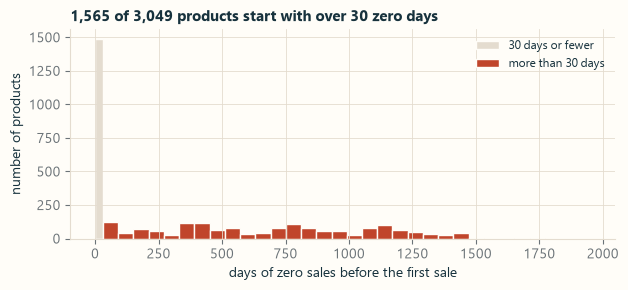

In [2]:
ca = sales[sales["state_id"] == "CA"]
items = ca.groupby(["item_id", "cat_id"])[days].sum()          # one row per product, the four stores added up
vals = items.values
first_sale = np.where((vals > 0).any(axis=1), (vals > 0).argmax(axis=1), vals.shape[1])
lead = pd.Series(first_sale, index=items.index.get_level_values("item_id"), name="leading_zero_days")
n_long = int((lead > 30).sum())
print(f"products with more than 30 zero days before the first sale: {n_long:,} of {len(lead):,} ({n_long / len(lead):.1%})")
print(lead.groupby(items.index.get_level_values("cat_id")).apply(lambda x: (x > 30).sum()).to_dict())

edges = np.r_[0, 31, np.arange(91, 1942 + 60, 60)]
with plt.rc_context(CREAM):
    fig, ax = plt.subplots(figsize=(6.4, 3.0))
    ax.hist(lead[lead <= 30], bins=edges, color=GRID, edgecolor=PAPER, label="30 days or fewer")
    ax.hist(lead[lead > 30], bins=edges, color=ACCENT, edgecolor=PAPER, label="more than 30 days")
    ax.set_xlabel("days of zero sales before the first sale")
    ax.set_ylabel("number of products")
    ax.set_title(f"{n_long:,} of {len(lead):,} products start with over 30 zero days", loc="left", fontsize=11, fontweight="bold")
    ax.legend(frameon=False, fontsize=8.5)
    fig.tight_layout()
    fig.savefig(FIGS / "plot_zero_values.png", dpi=200)
    plt.show()
written.append(FIGS / "plot_zero_values.png")

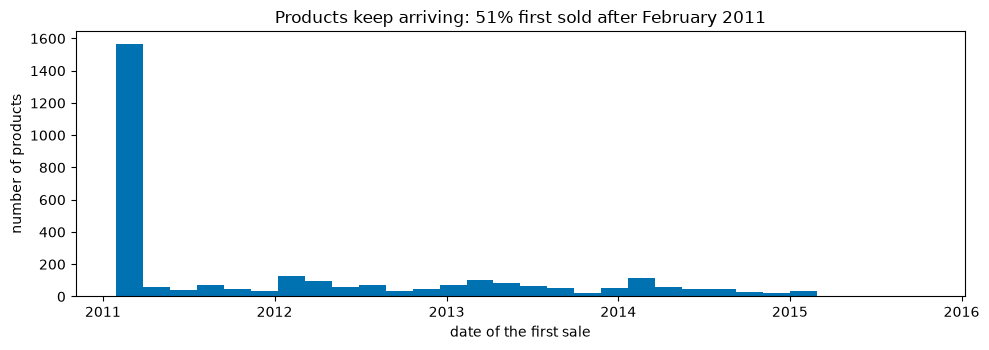

In [3]:
launch = pd.to_datetime(d2date.loc[[days[i] for i in first_sale[first_sale < len(days)]]].to_numpy())
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(launch, bins=30, color="#0072B2")
ax.set_xlabel("date of the first sale")
ax.set_ylabel("number of products")
ax.set_title(f"Products keep arriving: {(launch > pd.Timestamp('2011-03-01')).mean():.0%} first sold after February 2011")
fig.tight_layout()
fig.savefig(FIGS / "first_sale_dates.png")
written.append(FIGS / "first_sale_dates.png")
plt.show()

## One product before and after trimming

`FOODS_1_004` is a good example. In the raw file it sells nothing for more than a year, then starts at around 50
a day. We decompose it twice, with a weekly period: once on the raw series and once from its first sale.

In [4]:
foods = ca[ca["cat_id"] == "FOODS"].groupby("item_id")[days].sum().reset_index()
long_df = foods.melt(id_vars="item_id", var_name="d", value_name="sales")
long_df = long_df.merge(cal[["d", "date"]], on="d", how="left")
long_df["date"] = pd.to_datetime(long_df["date"])
long_df = long_df.sort_values(["item_id", "date"]).reset_index(drop=True)

raw = long_df[long_df["item_id"] == "FOODS_1_004"].set_index("date")["sales"]
first = raw[raw > 0].index.min()
print(f"FOODS_1_004: {(raw.index < first).sum()} zero days before its first sale on {first.date()}; "
      f"first sales after that: {raw[raw.index >= first].head(5).tolist()}")

FOODS_1_004: 403 zero days before its first sale on 2012-03-07; first sales after that: [1, 48, 50, 53, 56]


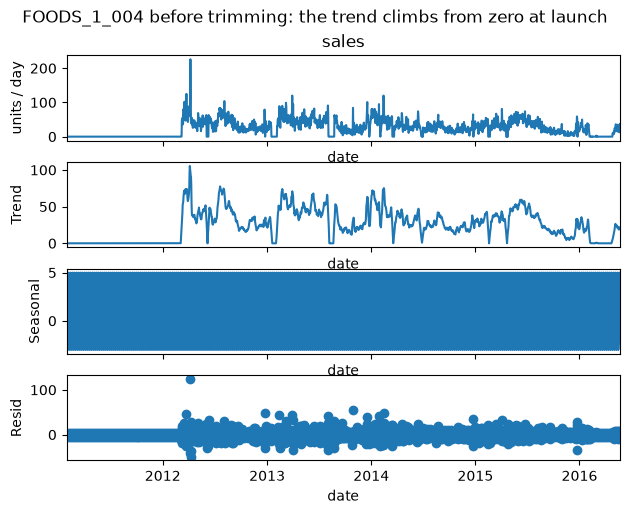

In [5]:
res = seasonal_decompose(raw, model="additive", period=7)
fig = res.plot()
fig.suptitle("FOODS_1_004 before trimming: the trend climbs from zero at launch", y=1.02)
for ax in fig.axes:
    ax.set_xlabel("date")
fig.axes[0].set_ylabel("units / day")
plt.savefig(FIGS / "foods_1_004_decomposition_before_trim.png", bbox_inches="tight")
written.append(FIGS / "foods_1_004_decomposition_before_trim.png")
plt.show()

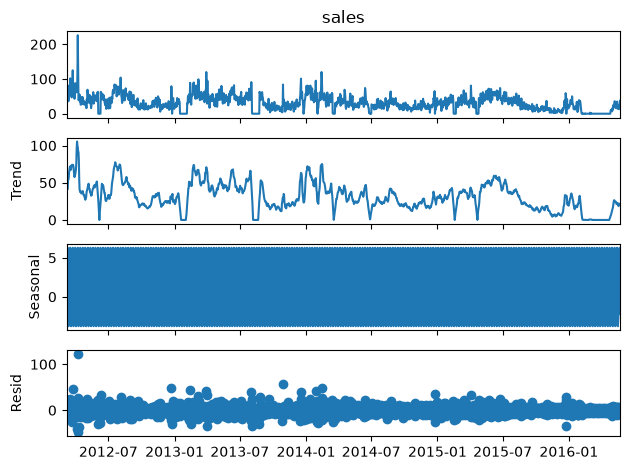

In [6]:
# the same decomposition from the first sale on (this is the figure notebook 00 used to save)
def trim_leading_zeros(df):
    """Keep only rows from an item's first non-zero sale date onward."""
    trimmed = []
    for item_id, grp in df.groupby("item_id"):
        grp = grp.sort_values("date")
        first_sale_idx = grp["sales"].to_numpy().nonzero()[0]
        if len(first_sale_idx) == 0:
            continue
        trimmed.append(grp.iloc[first_sale_idx[0]:])
    return pd.concat(trimmed, ignore_index=True)

trimmed = trim_leading_zeros(long_df)
series = trimmed[trimmed["item_id"] == "FOODS_1_004"].set_index("date")["sales"]
decomposition = seasonal_decompose(series, model="additive", period=7)
decomposition.plot()
plt.savefig(FIGS / "foods_1_004_decomposition.png")
written.append(FIGS / "foods_1_004_decomposition.png")
plt.show()

## Why it changes which products we pick

Our very first segmentation ran on the raw series. The leading zeros made launch-year products look erratic, so
fewer of them passed the XYZ cut: 300 FOODS products came out as AX or AY. After trimming the same rule gives 337.
We keep the raw series of that first selection on disk, because the dashboard uses it to show a product before and
after trimming.

In [7]:
def segment(df):
    st = df.groupby("item_id")["sales"].agg(total_sales="sum", mean_sales="mean", std_sales="std").reset_index()
    st["cv"] = st["std_sales"] / st["mean_sales"]
    st = st.sort_values("total_sales", ascending=False).reset_index(drop=True)
    st["cum_pct"] = st["total_sales"].cumsum() / st["total_sales"].sum()
    st["abc_class"] = pd.cut(st["cum_pct"], bins=[0, 0.7, 0.9, 1.0], labels=["A", "B", "C"])
    st["xyz_class"] = pd.cut(st["cv"], bins=[0, 0.5, 1.0, np.inf], labels=["X", "Y", "Z"])
    st["segment"] = st["abc_class"].astype(str) + st["xyz_class"].astype(str)
    return st

before = segment(long_df)
after = segment(trimmed)
first_pass = before[before["segment"].isin(["AX", "AY"])]["item_id"].tolist()
print("AX/AY before trimming:", before["segment"].value_counts()[["AX", "AY"]].to_dict(), "=", len(first_pass))
print("AX/AY after trimming: ", after["segment"].value_counts()[["AX", "AY"]].to_dict(), "=",
      int(after["segment"].isin(["AX", "AY"]).sum()))

long_df[long_df["item_id"].isin(first_pass)].to_csv(INTERIM / "scoped_sales_candidates.csv", index=False)
written.append(INTERIM / "scoped_sales_candidates.csv")

AX/AY before trimming: {'AX': 43, 'AY': 257} = 300
AX/AY after trimming:  {'AX': 57, 'AY': 280} = 337


## The zeros we keep

Trimming only removes zeros *before* the first sale. Zeros later on are real: a stockout, a slow day, a product
being phased out. The best seller in FOODS shows one such run.

In [8]:
best = trimmed[trimmed["item_id"] == "FOODS_3_090"].set_index("date")["sales"]
gap = best["2011-02-01":"2011-03-01"]
print("FOODS_3_090, February 2011:", gap.tolist())
print(f"share of zero days kept after trimming, all CA FOODS products: {(trimmed['sales'] == 0).mean():.1%}")

FOODS_3_090, February 2011: [240, 232, 290, 521, 467, 493, 271, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
share of zero days kept after trimming, all CA FOODS products: 20.0%


## What we found

1,565 of California's 3,049 products (51.3%) have more than 30 zero days before their first sale: 714 in FOODS, 303
in HOBBIES and 548 in HOUSEHOLD. Products keep arriving all through the five years, so this is not a quirk of the
first weeks of the data.

`FOODS_1_004` shows the damage clearly. It has 403 zero days before its first sale on 7 March 2012 and sells about
50 a day straight away. Decomposed raw, its "trend" climbs from zero, which looks exactly like a huge upward shift
at launch. A break detector would flag it and a model would learn a level that never existed. From the first sale
on, the trend is flat and the weekly pattern is easy to see.

The zeros also changed which products we chose. On the raw series 300 FOODS products were AX or AY; after trimming,
337. That is why notebook 02 trims before it segments.

Zeros after the first sale stay. `FOODS_3_090`, the top FOODS seller, sells hundreds a day and then nothing for
several weeks in February 2011, which looks like a stockout. Those zeros are part of what a store has to plan for.

## What comes next

`05_stationarity` tests whether the trimmed series wander or stay around a level.

In [9]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\figures\plot_zero_values.png 56 KB
outputs\figures\first_sale_dates.png 21 KB
outputs\figures\foods_1_004_decomposition_before_trim.png 53 KB
outputs\figures\foods_1_004_decomposition.png 51 KB
data\interim\scoped_sales_candidates.csv 19,256 KB
